# Sentiment Analysis & GAD-7 Correlation

This notebook performs the following sentiment analysis on the free recall data:
1. **DeltaDay1Pre** = Day 1 Pre (pos - neg)
2. **DeltaDay1Post** = Day 1 Post (pos - neg)
3. **DeltaDay2Pre** = Day 2 Pre (pos - neg)
4. **DeltaDay1** = DeltaDay1Post - DeltaDay1Pre
5. **DeltaDay1_comp** = Day 1 compound (post - pre)
6. **DeltaPost** = Day 2 compound - Day 1 Post compound

For each metric, we:
- Calculate paired / one-sample t-statistics to test for significant differences.
- Check for correlation (Pearson and Spearman) with GAD-7 score.
- Create swarm plots for each comparison.
- Create regplots for each correlation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data
df_nlp = pd.read_csv('../data/free_recall_nlp.csv')
df_survey = pd.read_csv('../data/survey.csv')

# Merge on Sub
df_merged = pd.merge(df_nlp, df_survey, on='Sub', how='inner')

# Convert to float and drop missing values where needed
cols_to_numeric = [
    'day_1_pre_pos', 'day_1_pre_neg', 'day_1_pre_compound',
    'day_1_post_pos', 'day_1_post_neg', 'day_1_post_compound',
    'day_2_pre_pos', 'day_2_pre_neg', 'day_2_pre_compound',
    'day_2_post_pos', 'day_2_post_neg', 'day_2_post_compound',
    'GAD7'
]
for col in cols_to_numeric:
    df_merged[col] = pd.to_numeric(df_merged[col], errors='coerce')

# Calculate Delta Variables
# 1. DeltaDay1Pre = day1 Pre(pos - neg)
df_merged['DeltaDay1Pre'] = df_merged['day_1_pre_pos'] - df_merged['day_1_pre_neg']

# 2. DeltaDay1Post = day1 Post(pos - neg)
df_merged['DeltaDay1Post'] = df_merged['day_1_post_pos'] - df_merged['day_1_post_neg']

# 3. DeltaDay2Pre = day2 Pre(pos - neg)
df_merged['DeltaDay2Pre'] = df_merged['day_2_pre_pos'] - df_merged['day_2_pre_neg']

# 4. DeltaDay1 = DeltaDay1Post - DeltaDay1Pre
df_merged['DeltaDay1'] = df_merged['DeltaDay1Post'] - df_merged['DeltaDay1Pre']

# 5. DeltaDay1_comp = day1 compound (post-pre)
df_merged['DeltaDay1_comp'] = df_merged['day_1_post_compound'] - df_merged['day_1_pre_compound']

# 6. DeltaPost = day2 compound - day1 Post compound
df_merged['DeltaPost'] = df_merged['day_2_post_compound'] - df_merged['day_1_post_compound']

print(f"Loaded and merged {len(df_merged)} subjects with GAD-7 scores.")


Loaded and merged 67 subjects with GAD-7 scores.


In [3]:
# Define comparisons
variables = [
    ('DeltaDay1Pre', 'day_1_pre_pos', 'day_1_pre_neg', 'Day 1 Pre: Pos vs Neg'),
    ('DeltaDay1Post', 'day_1_post_pos', 'day_1_post_neg', 'Day 1 Post: Pos vs Neg'),
    ('DeltaDay2Pre', 'day_2_pre_pos', 'day_2_pre_neg', 'Day 2 Pre: Pos vs Neg'),
    ('DeltaDay1', 'DeltaDay1Post', 'DeltaDay1Pre', 'Day 1: Post vs Pre Sentiment Delta'),
    ('DeltaDay1_comp', 'day_1_post_compound', 'day_1_pre_compound', 'Day 1 Compound: Post vs Pre'),
    ('DeltaPost', 'day_2_post_compound', 'day_1_post_compound', 'Post Compound: Day 2 vs Day 1')
]

t_test_results = []
for var, colA, colB, label in variables:
    df_valid = df_merged.dropna(subset=[colA, colB, var])
    n = len(df_valid)
    if n > 1:
        # Paired t-test between condition A and condition B
        t_stat, p_val = stats.ttest_rel(df_valid[colA], df_valid[colB])
        mean_val = df_valid[var].mean()
        std_val = df_valid[var].std()
        t_test_results.append({
            'Variable': var,
            'Label': label,
            'N': n,
            'Mean Delta': mean_val,
            'SD Delta': std_val,
            't-statistic': t_stat,
            'p-value': p_val
        })
    else:
        t_test_results.append({
            'Variable': var,
            'Label': label,
            'N': n,
            'Mean Delta': np.nan,
            'SD Delta': np.nan,
            't-statistic': np.nan,
            'p-value': np.nan
        })

df_t = pd.DataFrame(t_test_results)
print("=== T-TEST RESULTS ===")
print(df_t.to_string(index=False))


=== T-TEST RESULTS ===
      Variable                              Label  N  Mean Delta  SD Delta  t-statistic  p-value
  DeltaDay1Pre              Day 1 Pre: Pos vs Neg 67    0.037672  0.160361     1.922881 0.058812
 DeltaDay1Post             Day 1 Post: Pos vs Neg 64    0.049078  0.115113     3.410788 0.001136
  DeltaDay2Pre              Day 2 Pre: Pos vs Neg 67    0.083463  0.144128     4.740022 0.000012
     DeltaDay1 Day 1: Post vs Pre Sentiment Delta 64    0.007062  0.198680     0.284377 0.777054
DeltaDay1_comp        Day 1 Compound: Post vs Pre 64    0.175002  0.711467     1.967783 0.053499
     DeltaPost      Post Compound: Day 2 vs Day 1 64    0.127241  0.660547     1.541034 0.128317


In [4]:
corr_results = []
for var, colA, colB, label in variables:
    df_valid = df_merged.dropna(subset=[var, 'GAD7'])
    n = len(df_valid)
    if n > 2:
        r_pearson, p_pearson = stats.pearsonr(df_valid[var], df_valid['GAD7'])
        r_spearman, p_spearman = stats.spearmanr(df_valid[var], df_valid['GAD7'])
        corr_results.append({
            'Variable': var,
            'Label': label,
            'N': n,
            'Pearson r': r_pearson,
            'Pearson p': p_pearson,
            'Spearman r': r_spearman,
            'Spearman p': p_spearman
        })
    else:
        corr_results.append({
            'Variable': var,
            'Label': label,
            'N': n,
            'Pearson r': np.nan,
            'Pearson p': np.nan,
            'Spearman r': np.nan,
            'Spearman p': np.nan
        })

df_corr = pd.DataFrame(corr_results)
print("=== CORRELATION WITH GAD-7 ===")
print(df_corr.to_string(index=False))


=== CORRELATION WITH GAD-7 ===
      Variable                              Label  N  Pearson r  Pearson p  Spearman r  Spearman p
  DeltaDay1Pre              Day 1 Pre: Pos vs Neg 67  -0.129462   0.296414   -0.191058    0.121442
 DeltaDay1Post             Day 1 Post: Pos vs Neg 64  -0.005765   0.963939   -0.059515    0.640393
  DeltaDay2Pre              Day 2 Pre: Pos vs Neg 67  -0.143806   0.245643   -0.145886    0.238810
     DeltaDay1 Day 1: Post vs Pre Sentiment Delta 64   0.091892   0.470184    0.030842    0.808831
DeltaDay1_comp        Day 1 Compound: Post vs Pre 64   0.063189   0.619862    0.028496    0.823128
     DeltaPost      Post Compound: Day 2 vs Day 1 64   0.074214   0.560016    0.056901    0.655165


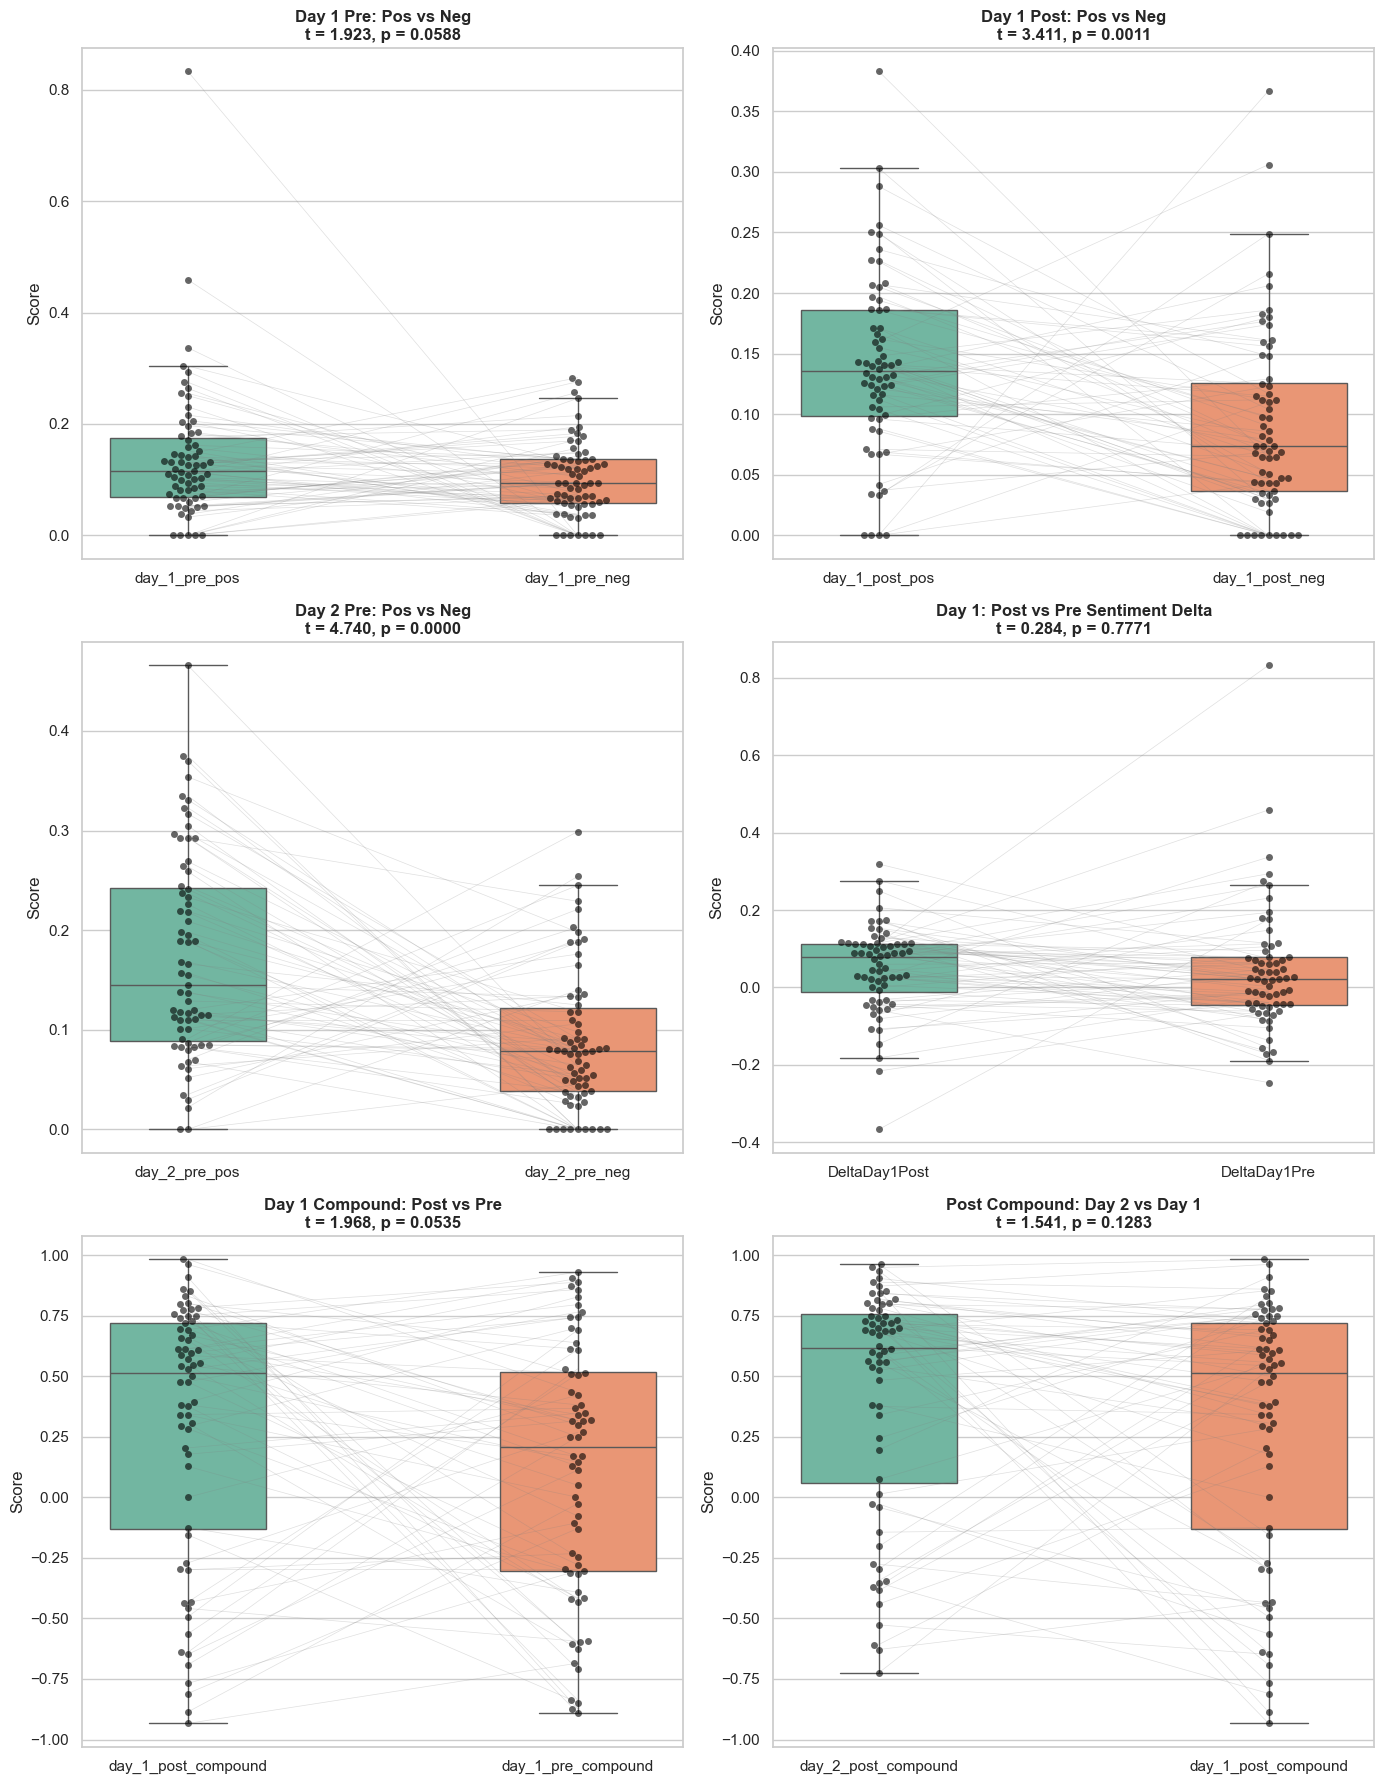

In [5]:
# Swarm plots for comparisons
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (var, colA, colB, label) in enumerate(variables):
    ax = axes[i]
    df_valid = df_merged.dropna(subset=[colA, colB])
    
    # Melt for swarmplot
    df_melt = df_valid.melt(id_vars=['Sub'], value_vars=[colA, colB], var_name='Condition', value_name='Score')
    
    # Plot boxplot + swarmplot
    sns.boxplot(x='Condition', y='Score', data=df_melt, ax=ax, width=0.4, palette='Set2', showfliers=False)
    sns.swarmplot(x='Condition', y='Score', data=df_melt, ax=ax, size=5, color='black', alpha=0.6)
    
    # Connecting paired observations
    y1 = df_valid[colA].values
    y2 = df_valid[colB].values
    for j in range(len(df_valid)):
        ax.plot([0, 1], [y1[j], y2[j]], color='gray', alpha=0.25, linestyle='-', linewidth=0.5)
        
    t_stat = df_t.loc[df_t['Variable'] == var, 't-statistic'].values[0]
    p_val = df_t.loc[df_t['Variable'] == var, 'p-value'].values[0]
    
    ax.set_title(f"{label}\nt = {t_stat:.3f}, p = {p_val:.4f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()


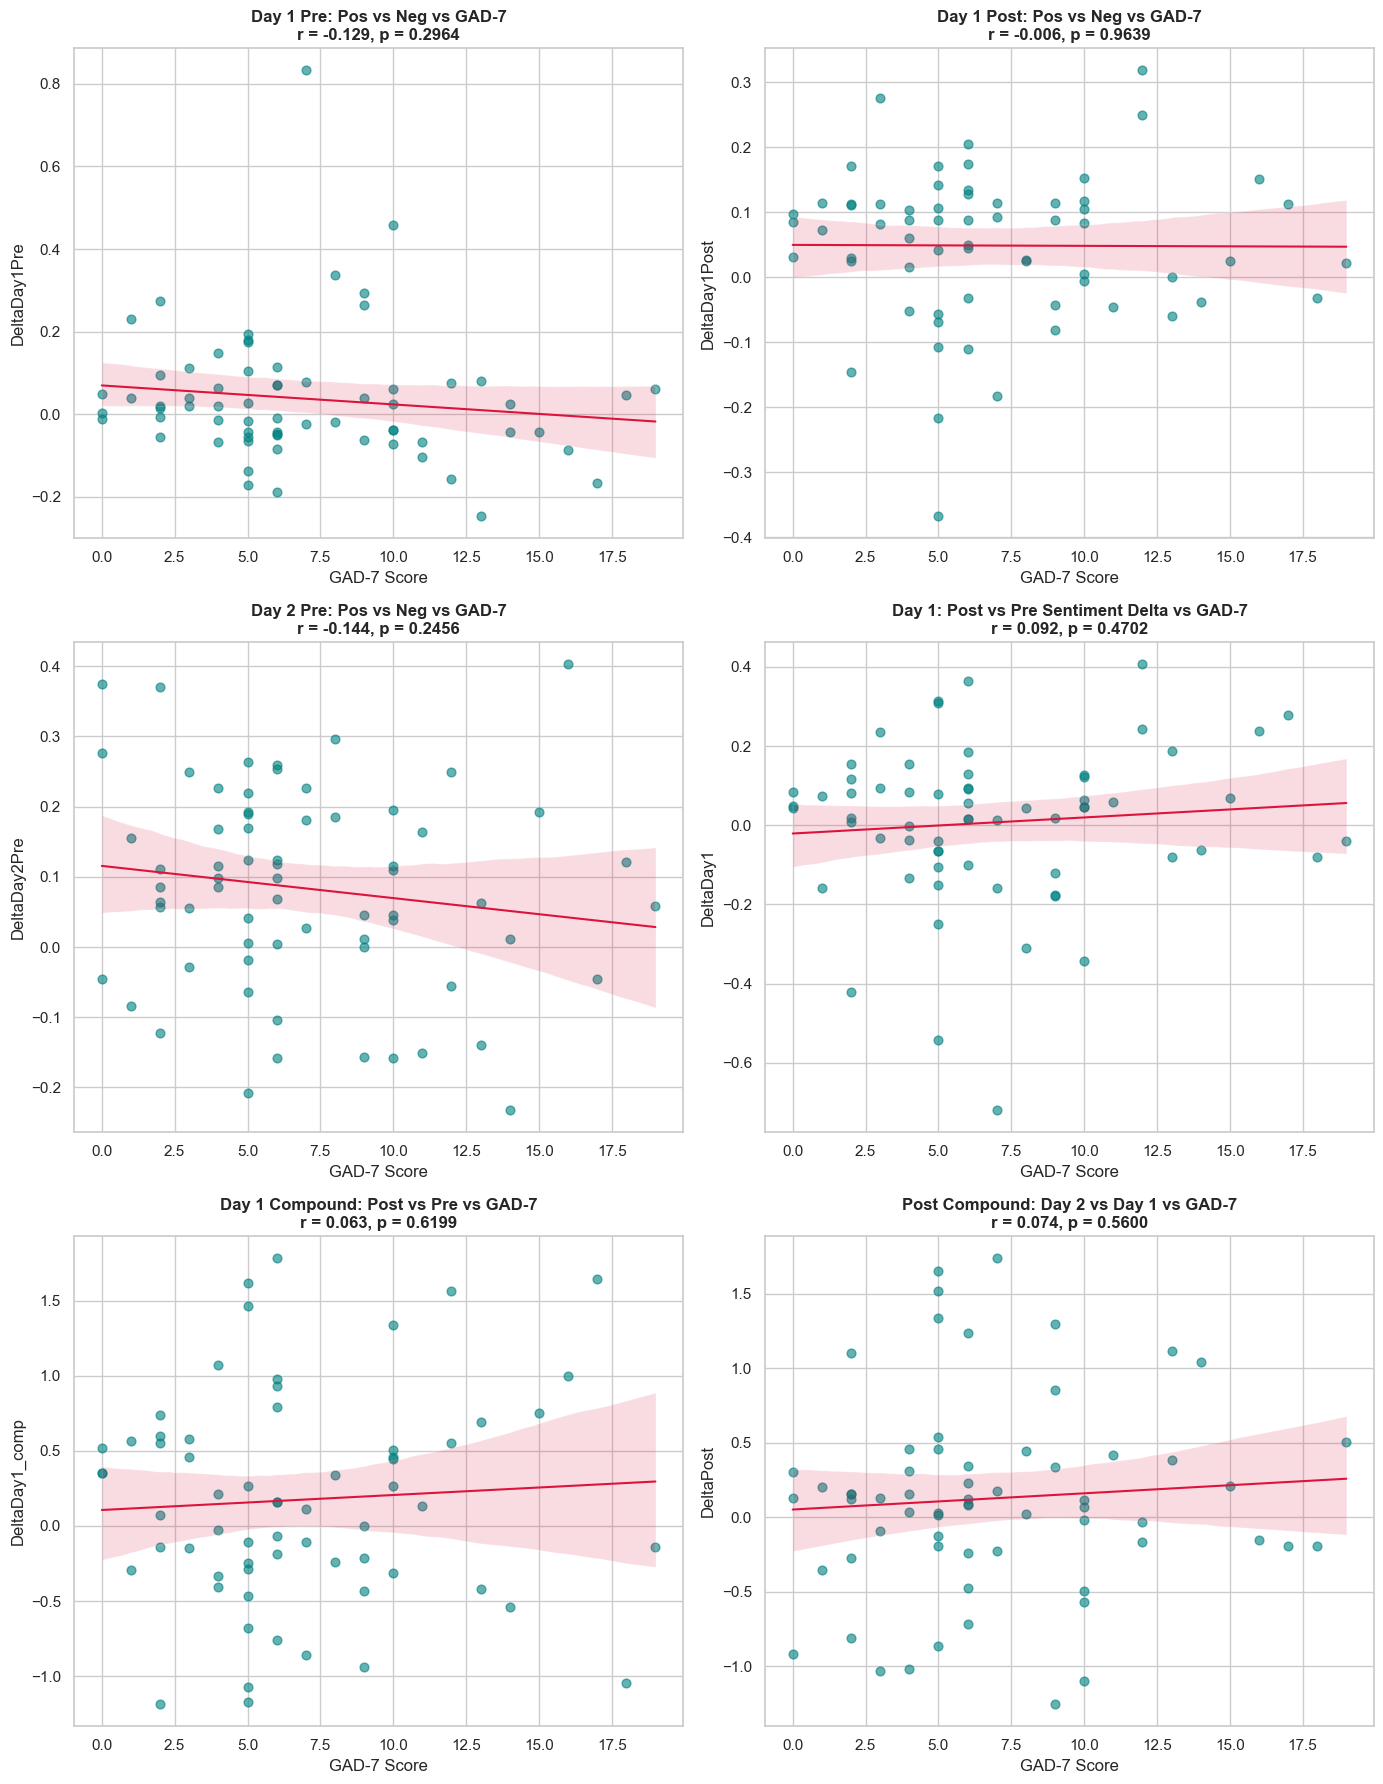

In [6]:
# Regplots for correlations with GAD-7
fig, axes = plt.subplots(3, 2, figsize=(14, 18))
axes = axes.flatten()

for i, (var, colA, colB, label) in enumerate(variables):
    ax = axes[i]
    df_valid = df_merged.dropna(subset=[var, 'GAD7'])
    
    # Plot regplot
    sns.regplot(x='GAD7', y=var, data=df_valid, ax=ax, color='teal', 
                scatter_kws={'alpha':0.6, 's':40}, line_kws={'color':'crimson', 'linewidth':1.5})
    
    r_val = df_corr.loc[df_corr['Variable'] == var, 'Pearson r'].values[0]
    p_val = df_corr.loc[df_corr['Variable'] == var, 'Pearson p'].values[0]
    
    ax.set_title(f"{label} vs GAD-7\nr = {r_val:.3f}, p = {p_val:.4f}", fontsize=12, fontweight='bold')
    ax.set_xlabel("GAD-7 Score")
    ax.set_ylabel(var)

plt.tight_layout()
plt.show()
